# Finding 2: Home Advantage Across European Competitions

Home-win rates differed across the five major European leagues and the UEFA Champions League during the 2024/2025 season.

This analysis compares home-win percentages across six competitions to determine whether the differences are statistically significant and whether the pattern changes when the Champions League is excluded.

In [7]:
import pandas as pd
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt
from pathlib import Path

### Testing Differences in Home-Win Rates

We use a chi-square test of independence to determine whether home-win rates differ significantly across the five major European leagues and the UEFA Champions League during the 2024/2025 season.

We first compare all six competitions, then repeat the test without the Champions League to check whether the results change when considering only domestic leagues.

In [4]:
df = pd.read_csv("data/football_matches_2024_2025.csv")
df = df[df["status"] == "FINISHED"].copy()

# Compare all six competitions
table = pd.crosstab(
    df["competition_name"],
    df["match_outcome"] == "Home Win"
)

chi2, p, dof, expected = chi2_contingency(table)
print(f"All six competitions: p = {p:.4f}")

# Repeat without Champions League
domestic = df[
    ~df["competition_name"].str.contains("Champions League")
]


table_domestic = pd.crosstab(
    domestic["competition_name"],
    domestic["match_outcome"] == "Home Win"
)

chi2, p, dof, expected = chi2_contingency(table_domestic)
print(f"Five domestic leagues: p = {p:.4f}")



All six competitions: p = 0.0404
Five domestic leagues: p = 0.1753


### Home-Win Percentages and Confidence Intervals

We calculate the home-win percentage for each of the six competitions to see how frequently home teams win. We also calculate 95% Wilson confidence intervals to show the uncertainty around each percentage and help us compare the competitions.

In [6]:
# Calculate home-win percentages by competition
summary = (
    df.assign(home_win=df["match_outcome"] == "Home Win")
    .groupby("competition_name")["home_win"]
    .agg(home_wins="sum", matches="count")
    .reset_index()
)

summary["home_win_pct"] = (
    summary["home_wins"] / summary["matches"] * 100
)

# Calculate 95% Wilson confidence intervals
lower, upper = proportion_confint(
    summary["home_wins"],
    summary["matches"],
    alpha=0.05,
    method="wilson"
)

summary["ci_lower"] = lower * 100
summary["ci_upper"] = upper * 100

print(summary.round(2).to_string(index=False))


     competition_name  home_wins  matches  home_win_pct  ci_lower  ci_upper
           Bundesliga        118      305         38.69     33.40     44.26
              La Liga        169      380         44.47     39.56     49.50
              Ligue 1        143      305         46.89     41.36     52.49
       Premier League        155      380         40.79     35.96     45.80
              Serie A        151      380         39.74     34.94     44.74
UEFA Champions League         96      189         50.79     43.72     57.83


Home-win percentages ranged from 38.69% in the Bundesliga to 50.79% in the UEFA Champions League, a difference of 12.10 percentage points. The Champions League had the highest observed home-win rate, while the Bundesliga had the lowest.

The 95% confidence intervals show uncertainty around these percentages. For example, the Champions League's estimated home-win rate was 50.79%, with a 95% confidence interval of 43.72% to 57.83%. Although the overall chi-square test found a statistically significant difference across competitions, these results do not establish which individual competitions differ significantly from each other

### Visualizing Home-Win Rates Across Competitions

We visualize home-win percentages across all six competitions with 95% confidence intervals. This allows us to compare the observed differences and the uncertainty surrounding each estimate.

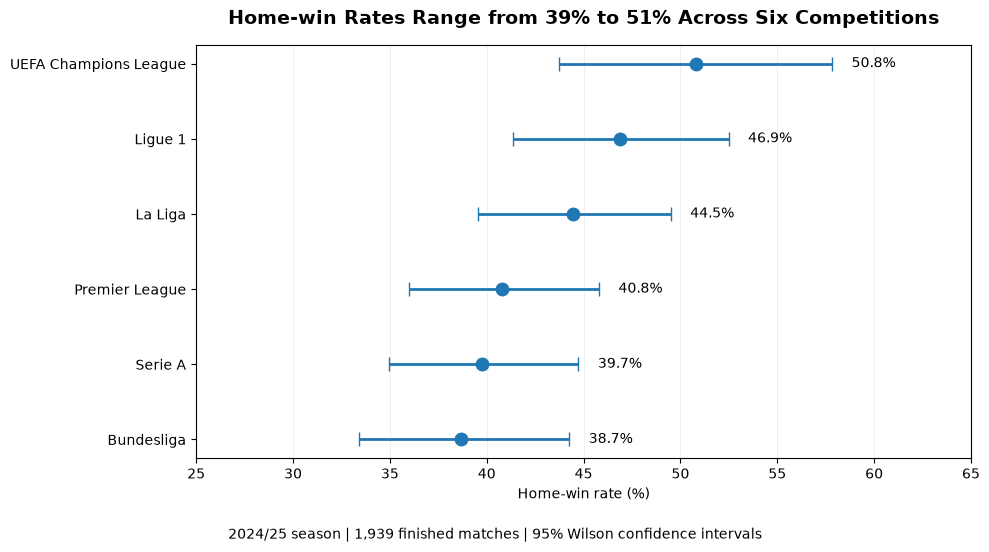

In [10]:

# Sort competitions by home-win percentage
plot_df = summary.sort_values("home_win_pct").reset_index(drop=True)

# Calculate confidence interval error bars
lower_error = plot_df["home_win_pct"] - plot_df["ci_lower"]
upper_error = plot_df["ci_upper"] - plot_df["home_win_pct"]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    plot_df["home_win_pct"],
    range(len(plot_df)),
    xerr=[lower_error, upper_error],
    fmt="o",
    markersize=9,
    capsize=5,
    linewidth=2
)

# Add percentage labels
for i, row in plot_df.iterrows():
    ax.text(
        row["ci_upper"] + 1,
        i,
        f'{row["home_win_pct"]:.1f}%',
        va="center"
    )

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["competition_name"])
ax.set_xlim(25, 65)
ax.set_xlabel("Home-win rate (%)")
ax.set_title(
    "Home-win Rates Range from 39% to 51% Across Six Competitions",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "2024/25 season | 1,939 finished matches | 95% Wilson confidence intervals",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

# Save figure for README
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/finding-two.png", dpi=300, bbox_inches="tight")

plt.show()


### Alternative Explanation and Robustness Check

Our original test grouped away wins and draws together as non-home wins. However, competitions may have different draw rates, which could affect the comparison.

To check whether our finding depends on this grouping, we repeat the chi-square test using all three match outcomes: home win, away win, and draw. We also compare the results with our earlier test excluding the Champions League.

In [9]:

# Compare all three match outcomes across six competitions
outcome_table = pd.crosstab(
    df["competition_name"],
    df["match_outcome"]
)

chi2, p, dof, expected = chi2_contingency(outcome_table)

print(outcome_table)
print(f"\nSix competitions (3 outcomes): p = {p:.4f}")

# Repeat for the five domestic leagues
domestic_table = pd.crosstab(
    domestic["competition_name"],
    domestic["match_outcome"]
)

chi2, p, dof, expected = chi2_contingency(domestic_table)

print(f"Five domestic leagues (3 outcomes): p = {p:.4f}")


match_outcome          Away Win  Draw  Home Win
competition_name                               
Bundesliga                  110    77       118
La Liga                     114    97       169
Ligue 1                     100    62       143
Premier League              132    93       155
Serie A                     121   108       151
UEFA Champions League        67    26        96

Six competitions (3 outcomes): p = 0.0105
Five domestic leagues (3 outcomes): p = 0.2240


When comparing home wins, away wins, and draws separately, the chi-square test found a statistically significant difference across all six competitions (p = 0.0105). However, when excluding the Champions League, the difference among the five domestic leagues was not statistically significant (p = 0.2240).

This supports our earlier finding that match outcomes vary across competitions, while showing that the result is sensitive to including the Champions League. One possible explanation is that the Champions League has a different competition format and team matchups than domestic leagues. However, these tests cannot establish that competition format caused the differences, or that the five domestic leagues have identical home advantage.